# Breast Cancer Survival Prediction
## Notebook 3: Voting Ensemble and Regression

Author: Armaan Khan

This notebook has two parts:

- **Part A** combines two of the models from Notebook 2 into a voting ensemble, to see if they predict mortality status better together.
- **Part B** uses regression to predict how many months the patients who died survived for, using a Multiple Linear Regression (MLR) and a Decision Tree Regressor (DTR).

In [1]:
# Importing the libraries needed for this notebook
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score)

RANDOM_STATE = 23
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Part A: Voting Ensemble

## 1. Loading the data and the base learners

I split the data with exactly the same settings as Notebook 2, so the ensemble is tested on the same patients as the other models.

In [2]:
# Loading the cleaned dataset from Notebook 1 and the models from Notebook 2
df = pd.read_csv("data/cleaned_breast_cancer.csv")
saved = joblib.load("models/classifiers.joblib")
feature_cols = saved["features"]

# Declaring the input features (X) and the target output (y)
X = df[feature_cols]
y = df["Died"]

# Splitting the dataset into training and test subsets, the same as Notebook 2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

(3212, 10) (803, 10)


## 2. Choosing the two base learners

I chose the tuned **Logistic Regression** and the pruned **Decision Tree** as the two base learners.

- They are very different types of model (one is parametric and the other is non-parametric), so they are likely to make different mistakes. This is what makes an ensemble work, as each model can cover for the other.
- They also have opposite strengths. After tuning, Logistic Regression finds a lot of the patients who died but with a low precision (0.28), while the pruned tree has a much higher precision (0.50) but finds very few of them. Combining them could give a better balance.
- The MLP was left out because its ROC-AUC (0.62) was lower than both of these models, so it was worse at ranking which patients were most at risk. It also can't be given a class_weight to deal with the imbalance.

In [3]:
# Declaring the two base learners
lr = saved["Logistic Regression"]
dt = saved["Decision Tree"]

# Importing the VotingClassifier, declaring the base learners and initialising the soft voting ensemble
base_learners = [("LogisticRegression", lr), ("DecisionTree", dt)]
ensemble_learner = VotingClassifier(base_learners, voting="soft")

# Training the voting ensemble on the training data
ensemble_learner.fit(X_train, y_train)
print("Voting ensemble trained")

Voting ensemble trained


Soft voting means the ensemble averages the probability of death given by each base learner, then predicts dead if the average is over 50%.

## 3. Evaluating the ensemble against the two base learners

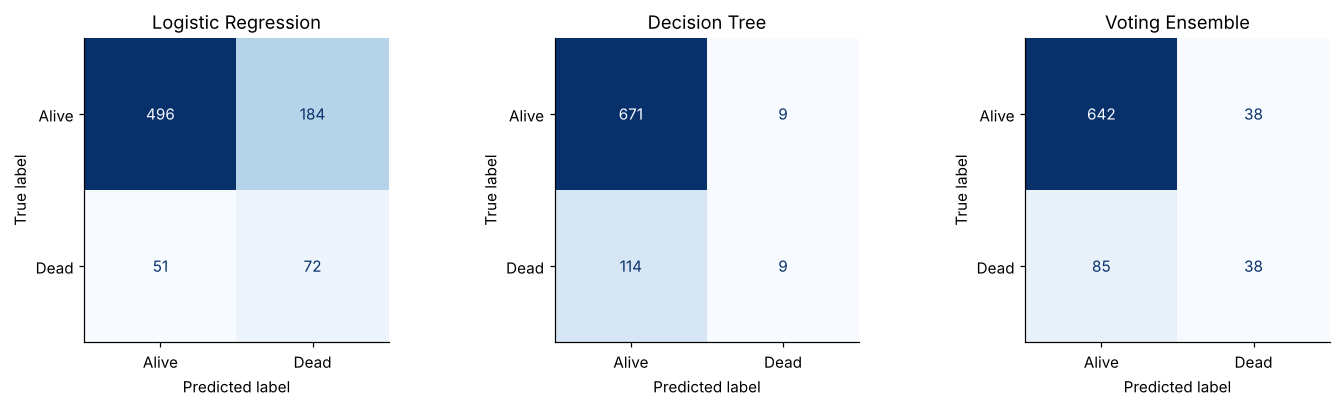

In [4]:
models = {"Logistic Regression": lr, "Decision Tree": dt, "Voting Ensemble": ensemble_learner}

# Plotting the test confusion matrices for the two base learners and the ensemble
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["Alive", "Dead"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("images/ensemble_confusion_matrices.png", bbox_inches="tight")
plt.show()

In [5]:
# Displaying the classification reports for the two base learners and the ensemble
for name, model in models.items():
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=["Alive", "Dead"]))

Logistic Regression
              precision    recall  f1-score   support

       Alive       0.91      0.73      0.81       680
        Dead       0.28      0.59      0.38       123

    accuracy                           0.71       803
   macro avg       0.59      0.66      0.59       803
weighted avg       0.81      0.71      0.74       803

Decision Tree
              precision    recall  f1-score   support

       Alive       0.85      0.99      0.92       680
        Dead       0.50      0.07      0.13       123

    accuracy                           0.85       803
   macro avg       0.68      0.53      0.52       803
weighted avg       0.80      0.85      0.80       803

Voting Ensemble
              precision    recall  f1-score   support

       Alive       0.88      0.94      0.91       680
        Dead       0.50      0.31      0.38       123

    accuracy                           0.85       803
   macro avg       0.69      0.63      0.65       803
weighted avg       0.82 

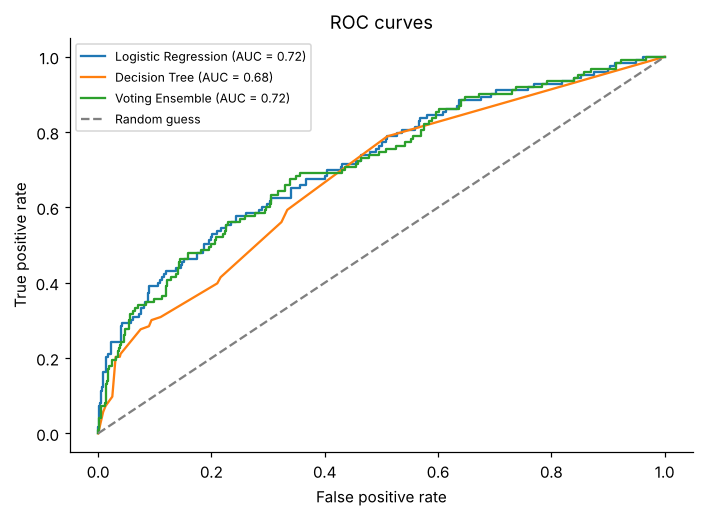

In [6]:
# Plotting the ROC curves for the two base learners and the ensemble
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probabilities):.2f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="Random guess")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("images/ensemble_roc_curves.png", bbox_inches="tight")
plt.show()

In [7]:
# Comparing the test scores for the dead class
rows = []
for name, model in models.items():
    predictions = model.predict(X_test)
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
        "Accuracy": accuracy_score(y_test, predictions),
        "Predicted dead": predictions.sum(),
        "Correctly predicted dead": ((predictions == 1) & (y_test == 1)).sum(),
    })
ensemble_scores = pd.DataFrame(rows).round(3)
ensemble_scores

,Model,Precision,Recall,F1-score,ROC-AUC,Accuracy,Predicted dead,Correctly predicted dead
0,Logistic Regression,0.281,0.585,0.380,0.720,0.707,256,72
1,Decision Tree,0.500,0.073,0.128,0.679,0.847,18,9
2,Voting Ensemble,0.500,0.309,0.382,0.716,0.847,76,38


1) Compared to the two base learners, the ensemble's F1-score (0.382) is about the same as Logistic Regression's (0.380) and far higher than the Decision Tree's (0.128). The biggest improvement is in precision: half of the patients the ensemble predicts as dead really did die (38 out of 76), compared to 72 out of 256 for Logistic Regression (0.28). Its recall (0.31) is lower than Logistic Regression's (0.59) but much higher than the Decision Tree's (0.07). The ROC-AUC of the ensemble (0.72) is about the same as Logistic Regression's and higher than the Decision Tree's (0.68).

2) and 3) I would recommend the voting ensemble for mortality prediction. It keeps the best F1-score while making far fewer false alarms than Logistic Regression, which matches the success criteria of making sure most of the positive predictions are correct. This means less time and resources would be wasted on patients who were wrongly flagged. The trade off is that it finds fewer of the patients who died than Logistic Regression, so if finding every possible death mattered more to the doctors than avoiding false alarms, Logistic Regression on its own would be the better choice.

# Part B: Predicting Survival Months

The research question for this part is whether machine learning has the potential to help doctors predict the survival months of the patients who are not going to survive breast cancer. So I only use the patients who died, and the target is Survival_Months.

## 4. The regression dataset

In [8]:
# Keeping only the patients who died
dataset = df[df["Died"] == 1]

# Declaring the input features (X) and the target (y), using the same features as the classification
X = dataset[feature_cols]
y = dataset["Survival_Months"]

# Displaying the dimensions and the feature names of the retained regression dataset
print(X.shape)
print(feature_cols)

(614, 10)
['Age', 'T_Stage', 'N_Stage', 'A_Stage', 'Grade', 'Tumor_Size', 'Estrogen_Status', 'Progesterone_Status', 'Regional_Node_Examined', 'Regional_Node_Positive']


## 5. Why use a Decision Tree Regressor and Multiple Linear Regression?

A benefit of using DTR is that it is highly interpretable, which allows healthcare professionals to visually trace how a prediction is made at each node for each patient. This easy to understand model helps healthcare professionals to make evidence-based choices, by structuring a complex decision into simple steps. Another benefit is that it isn't affected much by outliers, so it is adaptable to real-world datasets that are not perfectly clean.

A benefit of using MLR is that it clearly measures the influence of each feature on the outcome, which in this case is survival months. This makes MLR quite useful for identifying which variables matter most, which can be useful not only for deciding which variables to keep, but also for guiding medical decisions. Another benefit is that it is simple and easy to understand, which makes it a good baseline to compare more complex models against.

## 6. Building the two regression models

I use the same 80:20 split as for the classification. The decision tree is built fully grown first, then tuned with GridSearchCV using 5-fold cross-validation on the training data, to stop it from overfitting.

In [9]:
# Splitting the regression dataset into 80% training and 20% testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)
print("Training patients:", len(X_train), "| test patients:", len(X_test))

# Building the Multiple Linear Regression model (mean imputation inside the pipeline, as in Notebook 2)
mlr = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("model", LinearRegression()),
])
mlr.fit(X_train, y_train)

# Building a fully grown Decision Tree Regressor
dtr_full = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE)),
])
dtr_full.fit(X_train, y_train)

# Tuning the Decision Tree Regressor with GridSearchCV
dtr_params = {
    "model__max_depth": list(range(1, 11)),
    "model__criterion": ["squared_error", "absolute_error"],
    "model__splitter": ["best", "random"],
}
dtr_grid = GridSearchCV(dtr_full, dtr_params, scoring="neg_mean_squared_error",
                        cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
dtr_grid.fit(X_train, y_train)
dtr = dtr_grid.best_estimator_
print("Best hyperparameters for the tree:", {k.replace("model__", ""): v for k, v in dtr_grid.best_params_.items()})
print("Depth of the fully grown tree:", dtr_full.named_steps["model"].get_depth())

Training patients: 491 | test patients: 123


Best hyperparameters for the tree: {'criterion': 'absolute_error', 'max_depth': 1, 'splitter': 'best'}
Depth of the fully grown tree: 22


## 7. Learnable parameters of both models

### Multiple Linear Regression

The learnable parameters of MLR are the intercept and one coefficient for each feature. Each coefficient is the change in predicted survival months for a one unit increase in that feature, with everything else kept the same.

In [10]:
# Extracting the learnable parameters of the MLR model
linear = mlr.named_steps["model"]
coefficients = pd.Series(linear.coef_, index=feature_cols)
print("Intercept:", round(linear.intercept_, 2))
coefficients.round(2)

Intercept: 41.68


Age                       -0.14
T_Stage                    1.99
N_Stage                   -0.38
A_Stage                   -8.54
Grade                     -0.54
Tumor_Size                -0.07
Estrogen_Status           11.77
Progesterone_Status        4.95
Regional_Node_Examined    -0.05
Regional_Node_Positive     0.10
dtype: float64

In [11]:
# Writing out the MLR equation
terms = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.2f} x {name}" for name, c in coefficients.items())
print(f"Survival_Months = {linear.intercept_:.2f} {terms}")

Survival_Months = 41.68 - 0.14 x Age + 1.99 x T_Stage - 0.38 x N_Stage - 8.54 x A_Stage - 0.54 x Grade - 0.07 x Tumor_Size + 11.77 x Estrogen_Status + 4.95 x Progesterone_Status - 0.05 x Regional_Node_Examined + 0.10 x Regional_Node_Positive


### Decision Tree Regressor

The learnable parameters of a decision tree are the feature and threshold used at each split, and the predicted value at each leaf. As GridSearchCV chose the absolute_error criterion, the value at each leaf is the median survival months of the training patients that end up there.

|--- Estrogen_Status <= 0.50
|   |--- value: [27.00]
|--- Estrogen_Status >  0.50
|   |--- value: [48.00]



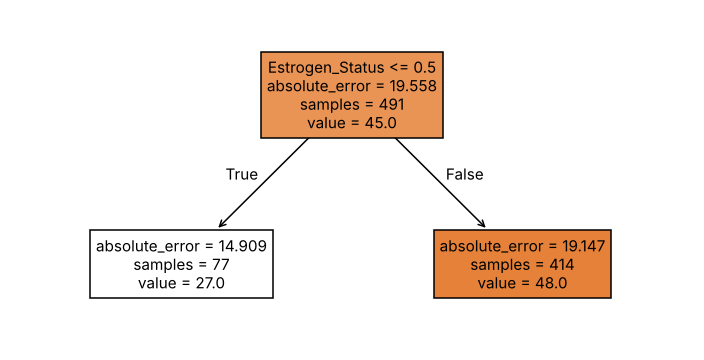

In [12]:
# Extracting the learnable parameters (splits and leaf values) of the tuned tree
print(export_text(dtr.named_steps["model"], feature_names=feature_cols))

# Plotting the tuned Decision Tree Regressor
fig, ax = plt.subplots(figsize=(8, 4))
plot_tree(dtr.named_steps["model"], feature_names=feature_cols, filled=True, fontsize=10, ax=ax)
plt.savefig("images/decision_tree_regressor.png", bbox_inches="tight", dpi=200)
plt.show()

The tuned tree only has one split, which is whether the patient is oestrogen positive. Patients who are oestrogen negative are predicted to survive 27 months, and patients who are oestrogen positive are predicted to survive 48 months. GridSearchCV chose a depth of 1 because every deeper tree did worse in cross-validation, which shows how hard survival months are to predict from these features. The fully grown tree is 22 levels deep, so it has memorised the training patients.

## 8. Evaluating the regression models

The success criteria is that the models are expected to make some errors in estimating the survival months, and the healthcare professionals want to find out which model's set of features better expresses the survival months.

| Metric | Use or don't use | Justification |
|---|---|---|
| MSE | Don't use | MSE penalises larger errors a lot more, but it is in squared months, which makes it hard to explain to a healthcare team. RMSE gives the same ranking of models in normal months, so I use that instead. |
| RMSE | Use | RMSE shows the typical size of the error in months, while still highlighting the predictions that are far off the actual survival months. |
| R² | Use | R² measures how much of the variation in survival months is explained by the features. This is exactly what the success criteria asks for, as it shows which model's set of features better expresses the survival months (Chicco, Warrens and Jurman, 2021). |

In [13]:
regression_models = {"MLR": mlr, "DTR (fully grown)": dtr_full, "DTR (tuned)": dtr}

# Calculating the test scores for each regression model
reg_rows = []
for name, model in regression_models.items():
    predictions = model.predict(X_test)
    reg_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R²": r2_score(y_test, predictions),
    })
regression_scores = pd.DataFrame(reg_rows).round(3)
regression_scores

,Model,MAE,MSE,RMSE,R²
0,MLR,17.185,447.320,21.150,0.196
1,DTR (fully grown),26.366,1017.293,31.895,-0.829
2,DTR (tuned),17.341,482.268,21.961,0.133


### Best regression model

Based on RMSE and R², MLR is the best regression model. It has the lowest RMSE (21.2 months) and the highest R² (0.20), compared to 22.0 and 0.13 for the tuned decision tree. This means the MLR's set of features expresses the survival months best, explaining about 20% of the variation, which is what the success criteria asks for. The fully grown tree is much worse than both, with a negative R² (-0.83), which means it does worse than just predicting the average survival months for everyone.

### Concerns about the metrics

Even the best model only explains 20% of the variation in survival months, so 80% is still unexplained. An RMSE of 21 months is large when the average survival of these patients is only 46 months, so the predictions shouldn't be used to tell a patient how long they have. The test set is also small (123 patients), so R² and RMSE could change quite a lot if different patients ended up in it. RMSE is also sensitive to a few very large errors, so a handful of patients who survived much longer or shorter than expected can make a model look worse than it is for most patients. Finally, R² is useful for comparing models on the same data (Chicco, Warrens and Jurman, 2021), but it doesn't show whether a model is worse for certain groups of patients, which matters in healthcare.

## 9. Predicting the survival months of a new patient

Patient B002567's breast cancer has been deemed terminal, and their record is below. I use both models to predict how many months they will survive for. Month of birth, sex, occupation, 6th stage and differentiated aren't used, as they were dropped in Notebook 1.

| Variable | Value |
|---|---|
| Age | 40 |
| T Stage | T2 |
| N Stage | N2 |
| 6th Stage | IIIC |
| Differentiated | Moderately differentiated |
| Grade | 2 |
| A Stage | Regional |
| Tumour Size | 32 |
| Estrogen Status | Positive |
| Progesterone Status | Negative |
| Regional Node Examined | 10 |
| Regional Node Positive | 2 |

In [14]:
# Creating the patient's record using the same mappings as Notebook 1
patient = pd.DataFrame([{
    "Age": 40, "T_Stage": 2, "N_Stage": 2, "A_Stage": 0, "Grade": 2, "Tumor_Size": 32,
    "Estrogen_Status": 1, "Progesterone_Status": 0, "Regional_Node_Examined": 10, "Regional_Node_Positive": 2,
}])[feature_cols]

# Predicting the patient's survival months with the tuned decision tree, and showing the path of rules it followed
tree = dtr.named_steps["model"]
node_path = tree.decision_path(patient.values).indices
for node in node_path:
    if tree.tree_.children_left[node] == -1:
        print(f"Leaf reached: predicted survival = {tree.tree_.value[node][0][0]:.1f} months")
    else:
        feature = feature_cols[tree.tree_.feature[node]]
        threshold = tree.tree_.threshold[node]
        value = patient.iloc[0][feature]
        direction = "yes" if value <= threshold else "no"
        print(f"Is {feature} <= {threshold:.2f}? The patient's value is {value}, so {direction}")

print("\nDecision tree prediction:", round(dtr.predict(patient)[0], 1), "months")

Is Estrogen_Status <= 0.50? The patient's value is 1, so no
Leaf reached: predicted survival = 48.0 months

Decision tree prediction: 48.0 months


In [15]:
# Predicting the patient's survival months with the MLR equation, step by step
total = linear.intercept_
print(f"Start with the intercept: {total:.2f}")
for name, c in coefficients.items():
    value = patient.iloc[0][name]
    contribution = round(c * value, 2) + 0.0
    total += c * value
    print(f"{'+' if c >= 0 else '-'} {abs(c):.2f} x {name} ({value}) = {contribution:+.2f}  ->  running total {total:.2f}")

print("\nMLR prediction:", round(mlr.predict(patient)[0], 1), "months")

Start with the intercept: 41.68
- 0.14 x Age (40) = -5.71  ->  running total 35.97
+ 1.99 x T_Stage (2) = +3.97  ->  running total 39.94
- 0.38 x N_Stage (2) = -0.76  ->  running total 39.18
- 8.54 x A_Stage (0) = +0.00  ->  running total 39.18
- 0.54 x Grade (2) = -1.08  ->  running total 38.10
- 0.07 x Tumor_Size (32) = -2.21  ->  running total 35.89
+ 11.77 x Estrogen_Status (1) = +11.77  ->  running total 47.65
+ 4.95 x Progesterone_Status (0) = +0.00  ->  running total 47.65
- 0.05 x Regional_Node_Examined (10) = -0.51  ->  running total 47.14
+ 0.10 x Regional_Node_Positive (2) = +0.21  ->  running total 47.35

MLR prediction: 47.4 months


**Decision tree:** the tree only asks one question, which is whether the patient is oestrogen positive. Patient B002567 is oestrogen positive, so they go down the right-hand branch, and the tree predicts they will survive about 48 months (4 years).

**MLR:** starting from the intercept of 41.68, each of the patient's values is multiplied by its coefficient and added on. The biggest effects are their age (40 x -0.14 = -5.71 months), being oestrogen positive (+11.77 months) and their T stage (2 x 1.99 = +3.97 months). Adding everything up gives a prediction of about 47 months.

Both models predict around 47 to 48 months for this patient. However, as both models have an RMSE of over 21 months, the real survival time could easily be around 2 years shorter or longer than this, so a doctor should only treat it as a rough guide.

# Conclusions

**Can machine learning help doctors predict which patients will survive breast cancer?** Partly. The best model, the soft voting ensemble of Logistic Regression and the Decision Tree, finds 31% of the patients who died, and half of the patients it predicts as dead really did die. That is far better than predicting that everyone survives, which finds none of them, but it is not reliable enough to be used without a doctor's judgement.

**Can it predict the survival months of the patients who won't survive?** Not very well. The best model (MLR) only explains about 20% of the variation in survival months and is typically around 21 months out, so it could only give a rough guide.

For both questions, the biggest limitation is the data. Information like the treatment each patient had isn't in the dataset, and adding it would probably improve the models more than any change to the algorithms.

## References

Chicco, D., Warrens, M.J. and Jurman, G. (2021). The coefficient of determination R-squared is more informative than SMAPE, MAE, MAPE, MSE and RMSE in regression analysis evaluation. *PeerJ Computer Science*, 7, e623. https://doi.org/10.7717/peerj-cs.623